### Stacking spectra collected with different instruments 

Let's suppose we observed the same target with several different instruments, under different wavelength ranges and different spectral resolution. In `easyspec`, it is straightforward to stack all of these spectra to get an improved result.

We start by importing the `analysis()` class from **easyspec**:


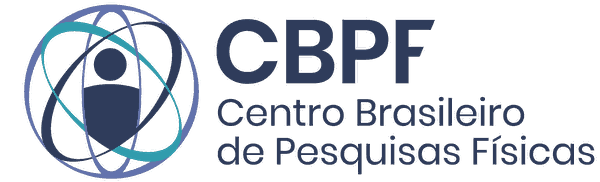

In [1]:
from pathlib import Path
from easyspec.analysis import analysis

analysis = analysis()

spectra_directory = Path("spec_different_instruments")      # the 16 spectra of the same target
output_directory = Path("results_stack")

There's no secret: we simply provide a list of paths to our spectra (e.g., `["/path/to/file.dat", "/path/to/file2.dat"]`), or a
directory containing all of them (here, `spec_different_instruments`). The files can be in the standard `easyspec` ".dat" format (two
to four columns separated by blank spaces: wavelength, flux density and, optionally, their uncertainties) or ".fits" files written by
`easyspec`; a list of (wavelength, flux) arrays is also accepted.

In this example, the 16 spectra of a blazar were taken with different instruments: they cover different wavelength ranges (from
3250 to 6990 Å in total) with different pixel sizes (from 2 to 10 Å). `stack_calib_spectra()` resamples all of them onto a common
wavelength grid, conserving the flux, and combines them pixel by pixel: in each pixel, only the spectra that cover it are used.

Stacked 16 spectra (median) onto 1885 pixels of 1.983 A (3250.5-6986.6 A); 1885 pixels with data.
  spectrum_1: reference
  spectrum_10: scale factor 1.005
  spectrum_11: scale factor 0.9907
  spectrum_12: scale factor 0.9434
  spectrum_13: scale factor 0.9369
  spectrum_14: scale factor 0.9879
  spectrum_15: scale factor 1.046
  spectrum_16: scale factor 1.068
  spectrum_2: scale factor 1.001
  spectrum_3: scale factor 0.9879
  spectrum_4: scale factor 0.9886
  spectrum_5: scale factor 1.01
  spectrum_6: scale factor 1.079
  spectrum_7: scale factor 1.043
  spectrum_8: scale factor 1.036
  spectrum_9: scale factor 0.9989


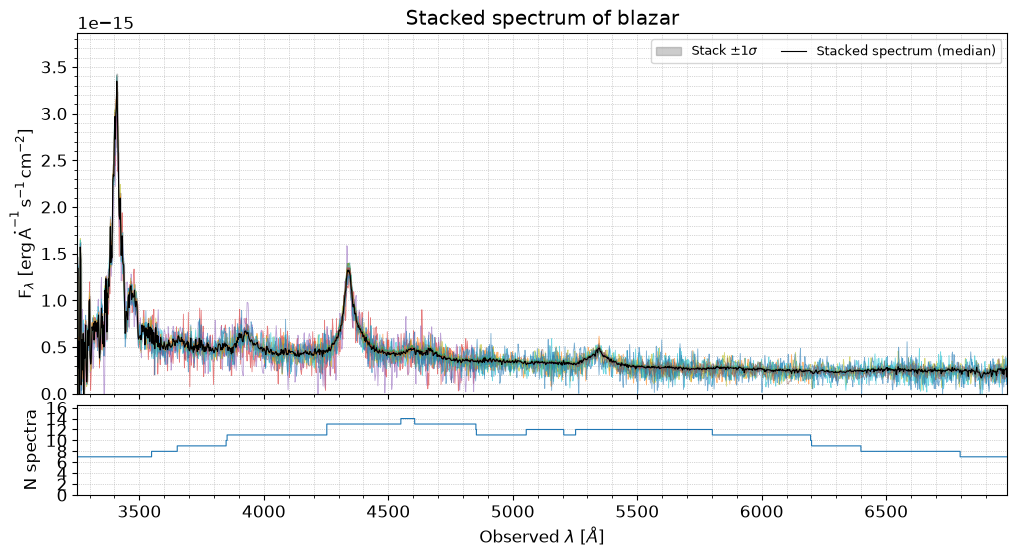

Stacked spectrum saved in results_stack/blazar_stacked_median.dat


In [2]:
wavelength_stack, flux_stack, flux_stack_error = analysis.stack_calib_spectra(
    spectra_directory,
    method="median",                  # "median" (robust to outliers), "mean", "weighted" (needs flux errors) or "sigma_clip"
    normalize="reference",            # scale each spectrum to the one with the best S/N (corrects slit losses); None: fluxes as they are
    target_name="blazar",             # used in the plot and in the name of the output file
    output_dir=output_directory,
    over_resolution_factor=1,         # grid step = the finest pixel size among the spectra (default)
    min_spectra=1,                    # minimum number of spectra in a pixel (pixels with fewer are set to NaN)
    save_file=True,                   # the stacked spectrum, in the same format as the input spectra
    plot=True,
    plot_overlayed_spectra=True,      # the individual spectra behind the stack, and the number of spectra in each pixel
    return_errors=True)               # also return the uncertainty of the stacked flux

The colored lines in the background are the 16 original spectra (after resampling and normalization), and the black line is the
stacked spectrum. The panel below shows how many spectra contribute to each pixel: the stack is less noisy where more spectra overlap.

Some details:

- **Methods**: `"median"` is robust against outliers in one spectrum (e.g. a residual cosmic ray), `"mean"` gives a slightly lower
  noise, `"weighted"` weights each spectrum by its inverse variance (it needs flux uncertainties in the files), and `"sigma_clip"` rejects,
  in each pixel, the points that deviate from the median before averaging (it needs at least 3 spectra in the pixel).
- **Normalization**: spectra from different nights or instruments rarely have exactly the same flux level (different slit losses or
  transparency). With `normalize="reference"`, each spectrum is scaled to the one with the highest signal-to-noise (here, the scale factors
  are between 0.94 and 1.08) and the flux calibration of that spectrum is kept. Use `normalize=None` if all the spectra are well
  calibrated, or `"unity"` to stack spectra of different objects (e.g. in their rest frames, with `redshifts=[z1, z2, z3, etc]`).
- **Wavelength grid**: the step of the common grid is the finest pixel size among the spectra (here ~2 Å). It can be made finer with
  `over_resolution_factor > 1`, but this does not add information: the extra pixels are interpolated and therefore correlated.

The outputs `wavelength_stack`, `flux_stack` and `flux_stack_error` contain the stacked spectrum, which can go directly to
`find_lines()` and `fit_lines()`, as in the other tutorials.